# 🍕 Pizza Delivery Time Predictor — **STUDENT ASSIGNMENT**
### Multivariate Linear Regression from Scratch

You work for **FastSlice Pizza 🍕**. The manager is tired of guessing how long a delivery will take and wants a model that predicts it from a few simple features. Your job: build one *from scratch*, then check your work against scikit-learn.

---
**Your tasks**
1. Explore the dataset.
2. Fill in the `MultiLinearRegression` class (gradient descent).
3. Train it, then validate against `sklearn.linear_model.LinearRegression`.
4. Experiment with the learning rate **α**.

> 💡 You've already seen simple linear regression (one variable). This is the natural next step: multiple inputs at once.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 5)

## 1. The dataset 🛵

| Feature | Meaning |
|---|---|
| `distance_km` | How far the customer lives from the shop |
| `num_pizzas` | How many pizzas in the order |
| `traffic_level` | 1 (empty roads) → 5 (gridlock) |
| `is_rush_hour` | 1 if ordered 7–9 PM, else 0 |

**Target:** `delivery_time_min`.

In [ ]:
def make_pizza_dataset(n=500, seed=42):
    rng = np.random.default_rng(seed)
    distance_km   = rng.uniform(0.5, 15, n)
    num_pizzas    = rng.integers(1, 8, n)
    traffic_level = rng.integers(1, 6, n)
    is_rush_hour  = rng.integers(0, 2, n)
    noise = rng.normal(0, 2.5, n)
    delivery_time = (
        8 + 2.2 * distance_km + 1.5 * num_pizzas
        + 3.0 * traffic_level + 5.0 * is_rush_hour + noise
    )
    return pd.DataFrame({
        'distance_km': distance_km.round(2),
        'num_pizzas': num_pizzas,
        'traffic_level': traffic_level,
        'is_rush_hour': is_rush_hour,
        'delivery_time_min': delivery_time.round(2),
    })

df = make_pizza_dataset()
df.head()

,distance_km,num_pizzas,traffic_level,is_rush_hour,delivery_time_min
0,11.72,6,3,1,50.16
1,6.86,6,2,0,34.66
2,12.95,4,2,0,43.96
3,10.61,7,2,0,42.22
4,1.87,1,3,1,24.62


       distance_km  num_pizzas  traffic_level  is_rush_hour  delivery_time_min
count   500.000000  500.000000     500.000000    500.000000         500.000000
mean      7.687400    4.044000       2.918000      0.472000          41.919000
std       4.158212    1.994497       1.439242      0.499715          11.351165
min       0.580000    1.000000       1.000000      0.000000          14.950000
25%       3.920000    2.000000       2.000000      0.000000          33.487500
50%       7.765000    4.000000       3.000000      0.000000          41.730000
75%      11.335000    6.000000       4.000000      1.000000          50.577500
max      14.990000    7.000000       5.000000      1.000000          73.240000

                   distance_km  num_pizzas  traffic_level  is_rush_hour  \
distance_km              1.000       0.045         -0.014        -0.026   
num_pizzas               0.045       1.000          0.079         0.060   
traffic_level           -0.014       0.079          1.000      

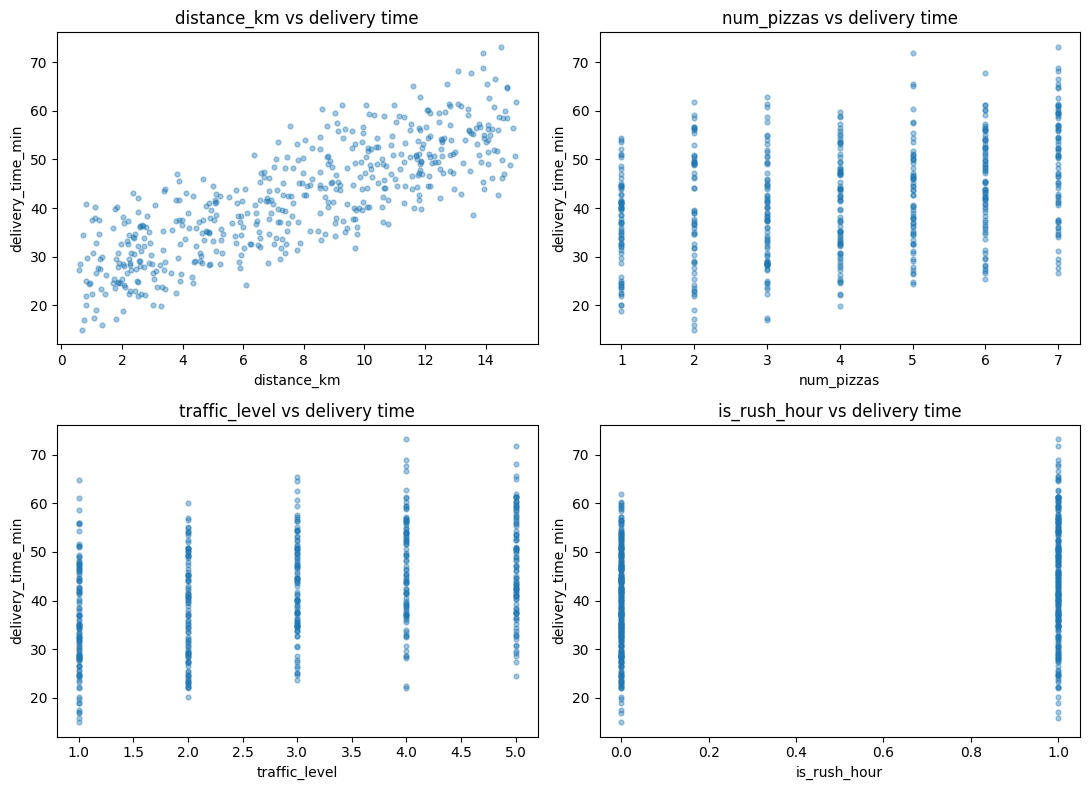

In [ ]:
# TODO: Explore the data. Try df.describe(), df.corr(), or scatter plots
#       of each feature against delivery_time_min.

print(df.describe())
print()
print(df.corr().round(3))

features = ['distance_km', 'num_pizzas', 'traffic_level', 'is_rush_hour']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.ravel(), features):
    ax.scatter(df[f], df['delivery_time_min'], alpha=0.4, s=12)
    ax.set_xlabel(f)
    ax.set_ylabel('delivery_time_min')
    ax.set_title(f'{f} vs delivery time')
plt.tight_layout()
plt.show()


## 2. Quick math recap 📐

With `n` features and parameters $\theta = (\theta_1, \dots, \theta_n)$ plus a bias $\theta_0$:

$$ \hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n $$

In vector form: $\hat{y} = X\theta + \theta_0$.

**Cost (MSE):** $\;J(\theta) = \dfrac{1}{m} \sum_{i=1}^{m}\bigl(\hat{y}^{(i)} - y^{(i)}\bigr)^2$

**Gradients:**
- $\dfrac{\partial J}{\partial \theta_j} = \dfrac{2}{m}\sum_i (\hat{y}^{(i)} - y^{(i)})\, x_j^{(i)}$
- $\dfrac{\partial J}{\partial \theta_0} = \dfrac{2}{m}\sum_i (\hat{y}^{(i)} - y^{(i)})$

**Update rule:** $\theta_j \leftarrow \theta_j - \alpha \dfrac{\partial J}{\partial \theta_j}$.

## 3. 🧑‍💻 Part A — Build the class

Fill in every `# TODO`. **Rules:**
- Only NumPy inside the class (no sklearn — that's for checking later).
- Keep track of the loss at every iteration so we can plot it.

In [ ]:
class MultiLinearRegression:
    """Multivariate linear regression trained with batch gradient descent."""

    def __init__(self, alpha=0.01, n_iters=1000):
        self.alpha = alpha
        self.n_iters = n_iters
        self.theta = None       # feature weights θ_1..θ_n, shape (n_features,)
        self.theta_0 = None     # scalar bias θ_0
        self.loss_history = []

    def fit(self, X, y):
        m, n = X.shape

        # TODO 1: initialize self.theta (zeros, length n) and self.theta_0 (0.0)
        self.theta   = np.zeros(n)
        self.theta_0 = 0.0
        self.loss_history = []

        for i in range(self.n_iters):
            # TODO 2: compute predictions   y_hat = X θ + θ_0
            y_hat = X @ self.theta + self.theta_0

            # TODO 3: compute the error  (y_hat - y)
            error = y_hat - y

            # TODO 4: compute gradients  dtheta  and  dtheta_0
            dtheta   = (2 / m) * (X.T @ error)
            dtheta_0 = (2 / m) * np.sum(error)

            # TODO 5: update self.theta and self.theta_0 using the learning rate
            self.theta   = self.theta - self.alpha * dtheta
            self.theta_0 = self.theta_0 - self.alpha * dtheta_0

            # TODO 6: record the MSE loss for this iteration
            loss = np.mean(error ** 2)
            self.loss_history.append(loss)

        return self

    def predict(self, X):
        # TODO 7: return X θ + θ_0
        return X @ self.theta + self.theta_0

    def score(self, X, y):
        """R² — same formula sklearn uses."""
        # TODO 8: implement R² = 1 - SS_res / SS_tot
        y_pred = self.predict(X)
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        return 1 - ss_res / ss_tot

## 4. Prepare the data

**Why standardize?** `distance_km` goes up to 15 but `is_rush_hour` is 0 or 1. Gradient descent *hates* that mismatch — one feature would dominate the updates.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns='delivery_time_min').values
y = df['delivery_time_min'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f'Train size: {X_train_s.shape},  Test size: {X_test_s.shape}')

Train size: (400, 4),  Test size: (100, 4)


## 5. Part B — Train your model 🚀

In [ ]:
# TODO: create a MultiLinearRegression with alpha=0.05 and n_iters=1000,
#       fit it on (X_train_s, y_train), then print θ, θ_0, and train/test R².
model = MultiLinearRegression(alpha=0.05, n_iters=1000)
model.fit(X_train_s, y_train)

print('theta   :', np.round(model.theta, 4))
print('theta_0 :', round(model.theta_0, 4))
print('Train R²:', round(model.score(X_train_s, y_train), 4))
print('Test  R²:', round(model.score(X_test_s, y_test), 4))

theta   : [9.2383 3.0995 4.3385 2.5599]
theta_0 : 42.0511
Train R²: 0.9495
Test  R²: 0.9323


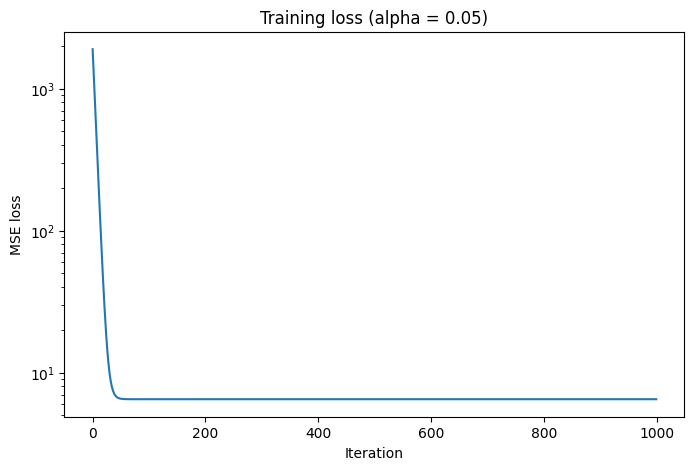

In [ ]:
# TODO: plot the loss curve (model.loss_history). Does it flatten?
plt.plot(model.loss_history)
plt.xlabel('Iteration')
plt.ylabel('MSE loss')
plt.title('Training loss (alpha = 0.05)')
plt.yscale('log')
plt.show()

## 6. Part C — Validate against scikit-learn 🔬

If your implementation is correct, the coefficients and predictions should be *very* close to sklearn's (not identical — sklearn solves it analytically; you used gradient descent).

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# TODO: fit sklearn's LinearRegression on (X_train_s, y_train).
#       Build a side-by-side comparison of your θ vs sklearn's coef_,
#       and compare θ_0 vs intercept_.
#       Then compare test MSE and R² for both models.
sk = LinearRegression().fit(X_train_s, y_train)

feature_names = ['distance_km', 'num_pizzas', 'traffic_level', 'is_rush_hour']
coef_df = pd.DataFrame({
    'feature': feature_names,
    'my_theta': model.theta,
    'sklearn_coef': sk.coef_,
})
coef_df['abs_diff'] = (coef_df['my_theta'] - coef_df['sklearn_coef']).abs()
print(coef_df.round(5))
print(f'\ntheta_0: mine = {model.theta_0:.5f} | sklearn intercept_ = {sk.intercept_:.5f}')

my_pred = model.predict(X_test_s)
sk_pred = sk.predict(X_test_s)
summary = pd.DataFrame({
    'Test MSE': [mean_squared_error(y_test, my_pred), mean_squared_error(y_test, sk_pred)],
    'Test R²':  [r2_score(y_test, my_pred), r2_score(y_test, sk_pred)],
}, index=['Mine (GD)', 'sklearn'])
print()
print(summary.round(5))


         feature  my_theta  sklearn_coef  abs_diff
0    distance_km   9.23827       9.23827       0.0
1     num_pizzas   3.09954       3.09954       0.0
2  traffic_level   4.33851       4.33851       0.0
3   is_rush_hour   2.55994       2.55994       0.0

theta_0: mine = 42.05112 | sklearn intercept_ = 42.05112

           Test MSE  Test R²
Mine (GD)    8.7408  0.93228
sklearn      8.7408  0.93228


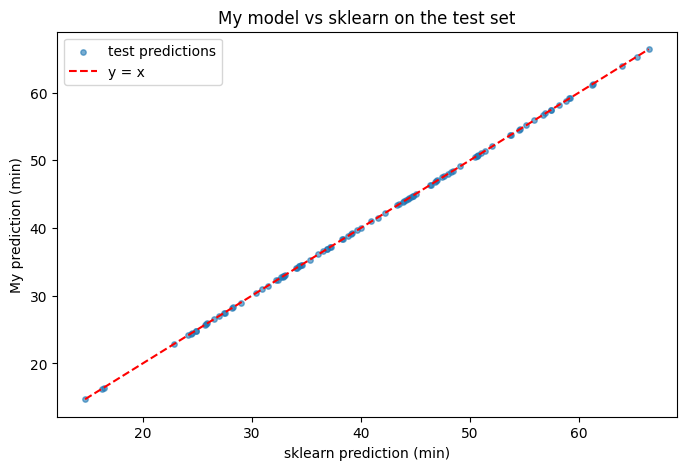

In [ ]:
# TODO: scatter your test predictions against sklearn's test predictions.
#       Add a y = x reference line. The clouds should lie on top of each other.
plt.scatter(sk_pred, my_pred, alpha=0.6, s=15, label='test predictions')
lims = [min(sk_pred.min(), my_pred.min()), max(sk_pred.max(), my_pred.max())]
plt.plot(lims, lims, 'r--', label='y = x')
plt.xlabel('sklearn prediction (min)')
plt.ylabel('My prediction (min)')
plt.title('My model vs sklearn on the test set')
plt.legend()
plt.show()

## 7. Part D — The α playground 🎛️

- **Too small** → learns correctly but painfully slow.
- **Just right** → smooth, fast convergence.
- **Too large** → bounces around, or explodes to infinity 💥.

Try `[0.0005, 0.01, 0.05, 0.1, 0.5]` and see for yourself.

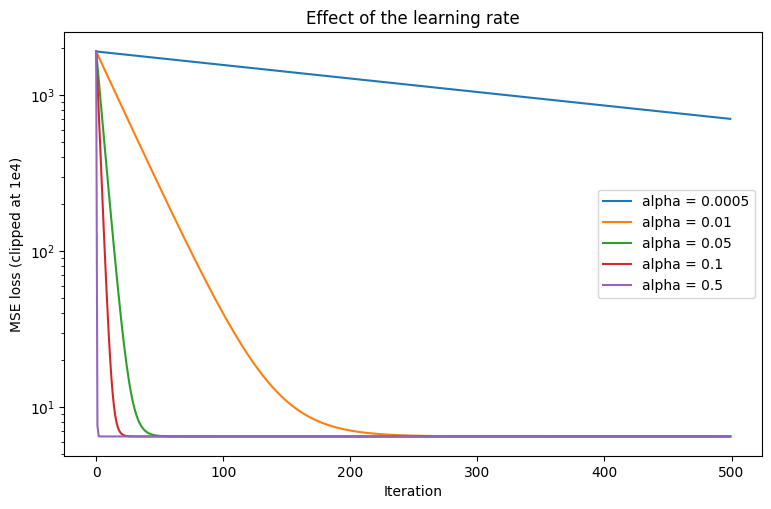

    alpha  final_loss   test_R2
0  0.0005  702.093167 -4.268837
1  0.0100    6.488159  0.932288
2  0.0500    6.488155  0.932281
3  0.1000    6.488155  0.932281
4  0.5000    6.488155  0.932281


In [ ]:
alphas = [0.0005, 0.01, 0.05, 0.1, 0.5]

# TODO: for each α, train a MultiLinearRegression with n_iters=500,
#       plot its loss curve on a shared figure (log y-axis helps),
#       and collect final loss + test R² into a summary DataFrame.
#
# Hint: use np.clip(losses, None, 1e4) before plotting so one blow-up
#       doesn't ruin the axis.
results = []
plt.figure(figsize=(9, 5.5))
for a in alphas:
    with np.errstate(all='ignore'):
        m_a = MultiLinearRegression(alpha=a, n_iters=500).fit(X_train_s, y_train)
        r2_a = m_a.score(X_test_s, y_test)
    losses = np.nan_to_num(np.array(m_a.loss_history), nan=1e4, posinf=1e4)
    plt.plot(np.clip(losses, None, 1e4), label=f'alpha = {a}')
    results.append({'alpha': a, 'final_loss': m_a.loss_history[-1], 'test_R2': r2_a})

plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('MSE loss (clipped at 1e4)')
plt.title('Effect of the learning rate')
plt.legend()
plt.show()

alpha_summary = pd.DataFrame(results)
print(alpha_summary)

## 8. 🤔 Reflection questions

Answer in the markdown cell below — a few sentences each.

1. Which α converged fastest? Which one failed (or nearly failed)? What does each loss curve look like?
2. Compare your learned θ with sklearn's. Which feature has the biggest effect on delivery time? Does that make intuitive sense?
3. We standardized the features before training. What happens if you skip that step? *(Try training on `X_train` instead of `X_train_s`.)*
4. **Bonus:** Add an L2 regularization term $\lambda \|\theta\|^2$ to the cost. How does it change θ? Which λ makes the biggest difference?

---
🎉 **Submit:** this notebook, with every TODO filled in and the reflection questions answered.

### Your reflections
*(double-click to edit)*

1. **Learning rate.** α = 0.5 converged fastest (loss within 1% of its final value after ~2 iterations), then 0.1 (~24), 0.05 (~49) and 0.01 (~256). α = 0.0005 nearly failed: it is stable but so slow that after 500 iterations the loss is still ~702 (vs ~6.49 for the others) and test R² is negative (≈ -4.3). The curves for 0.01–0.5 drop steeply and then flatten at the same floor (MSE ≈ 6.49, which is roughly the noise variance of 2.5² ≈ 6.25); 0.0005 is a slow, nearly straight decline on the log axis. None of the tested values actually blew up: with standardized features the stability limit is above 0.5, though a much larger α would eventually diverge.
2. **θ vs sklearn.** The coefficients, intercept, test MSE (≈ 8.74) and test R² (≈ 0.932) match sklearn to 5 decimal places, so the implementation is correct. On standardized features `distance_km` has by far the largest effect (θ ≈ 9.24 min per 1 std ≈ 4.2 km), followed by `traffic_level` (≈ 4.34), `num_pizzas` (≈ 3.10) and `is_rush_hour` (≈ 2.56). This makes intuitive sense: distance is the main driver of travel time, and it also had the highest correlation with the target (≈ 0.81). Note these θ are per standard deviation; in original units the true effects are 2.2 min/km, 1.5 min/pizza, 3 min/traffic level and 5 min for rush hour.
3. **Skipping standardization.** With α = 0.05 on the raw features the loss overflows to NaN, because `distance_km` (up to 15) makes the loss surface very steep along that axis, so the step is too large. Using a tiny α = 0.001 avoids the explosion but then convergence is slow and uneven: after 1000 iterations the loss (~11.4) is still above the ~6.5 floor and test R² is only ≈ 0.889, with θ not yet at the optimum. Standardizing puts all features on a similar scale so one learning rate works well for all of them.
4. **Bonus (L2).** Adding λ‖θ‖² shrinks all weights toward zero (the bias is not penalized). Small λ (0.01–0.1) barely changes θ and slightly improves test R² (≈ 0.934 → 0.938), while λ = 1 already shrinks the weights by about half (distance ≈ 4.6) and drops R² to ≈ 0.74, and λ = 10 over-regularizes (R² ≈ 0.17). This dataset is clean and low-dimensional with no overfitting, so regularization is mostly unnecessary; λ ≈ 0.1 is the best value tried, and λ = 1 → 10 make the biggest (harmful) difference.